# How Neural Networks Learn - Concepts

A spam filter can fit its training emails better without making better review decisions on new messages. We connect feedback from a labelled email to parameter updates, then ask which training choices generalize. One email is one observation: **0 = ham, 1 = spam**.

In this notebook, we will:
1. Explain loss, gradients and simultaneous parameter updates.
2. Distinguish an epoch, a parameter-update step and a retained checkpoint.
3. Interpret learning rate, capacity and regularization using training and validation evidence.
4. Distinguish probability loss from a thresholded review policy's business costs.

This accompanies **SW07 Lecture 2: How Neural Networks Learn**. Prerequisites are sigmoid/ReLU predictions, training/validation/test splits, precision and recall. Gradient rules are supplied; no calculus derivation is required. Read the idea, formula and small example in that order. All demonstration code is provided.

Choose one short worked example for the lecture's 10-minute demonstration slot. The complete [exercise](how_neural_networks_learn_exercise.ipynb) is a separate practical; check it with the [solution](how_neural_networks_learn_solution.ipynb).

## Libraries and settings

The small demonstrations are constructed illustrations, not measured spam-filter performance. They need only NumPy, pandas and matplotlib. The practical additionally uses scikit-learn and the repository's local feature-only email CSV; no raw emails or download are required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
np.random.seed(SEED)

## 1. Retain the right checkpoint

A lower training loss does not guarantee better predictions on new emails. A **checkpoint** is a saved set of parameter values. Choose a checkpoint using validation evidence, not the smallest training loss.

For the constructed curves below, the validation minimum is at epoch 20. With **patience of five complete epochs** without improvement, stop after epoch 25 and restore epoch 20's weights. Stopping time and best checkpoint are different. The dotted continuation is hypothetical.

Binary cross-entropy (BCE) evaluates predicted probabilities. Lower BCE does not necessarily mean fewer false positives, lower thresholded cost or better future performance. No email predictions are measured by these illustrative curves.

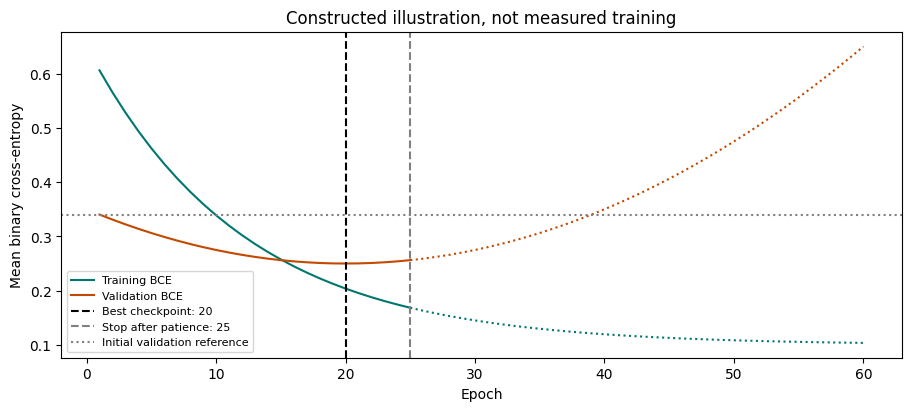

,epoch,training_bce,validation_bce
19,20,0.2039,0.2500
24,25,0.1685,0.2562
59,60,0.1037,0.6500


In [2]:
epochs = np.arange(1, 61)
training_bce = 0.55 * np.exp(-epochs / 12) + 0.1
validation_bce = 0.25 + 0.00025 * (epochs - 20) ** 2
best_epoch = int(epochs[np.argmin(validation_bce)])
patience = 5
stopping_epoch = best_epoch + patience

figure, axis = plt.subplots(figsize=(9, 4), constrained_layout=True)
for values, name, color in [(training_bce, 'Training BCE', '#00776E'),
                            (validation_bce, 'Validation BCE', '#C34800')]:
    observed = epochs <= stopping_epoch
    continued = epochs >= stopping_epoch
    axis.plot(epochs[observed], values[observed], label=name, color=color)
    axis.plot(epochs[continued], values[continued], linestyle=':', color=color)
axis.axvline(best_epoch, color='black', linestyle='--', label=f'Best checkpoint: {best_epoch}')
axis.axvline(stopping_epoch, color='gray', linestyle='--', label=f'Stop after patience: {stopping_epoch}')
axis.axhline(validation_bce[0], color='gray', linestyle=':', label='Initial validation reference')
axis.set(xlabel='Epoch', ylabel='Mean binary cross-entropy',
         title='Constructed illustration, not measured training')
axis.legend(fontsize=8)
plt.show()
illustration = pd.DataFrame({'epoch': epochs, 'training_bce': training_bce,
                             'validation_bce': validation_bce})
display(illustration.loc[illustration.epoch.isin([best_epoch, stopping_epoch, 60])].round(4))

## 2. Backpropagation computes gradients; an optimizer updates parameters

For input $x$, hidden activation $h$, output score $z$ and predicted spam probability $p$:

$$h=\operatorname{ReLU}(w_1x+b_1),\qquad z=w_2h+b_2,\qquad p=\frac{1}{1+\exp(-z)}.$$

The weights are $w_1,w_2$ and biases $b_1,b_2$. ReLU keeps a positive score and replaces a negative score with zero. For label $y$ (0 or 1), BCE is

$$L=-[y\ln(p)+(1-y)\ln(1-p)].$$

A gradient describes how a small parameter change affects loss. With sigmoid and BCE, output feedback is $g=p-y$. Multiply feedback by the original connecting weight to propagate it backward. A weight gradient also multiplies by that connection's input; a bias gradient does not. ReLU passes feedback here because its input is positive.

**Worked example:** $x=2$, $y=1$, initial $(w_1,b_1,w_2,b_2)=(0.5,0,0.4,-0.4)$. The forward pass gives $h=1$, $z=0$, $p=0.5$ and BCE approximately 0.693. Output feedback is -0.5; hidden feedback is -0.2. Gradients in parameter order are $(-0.4,-0.2,-0.5,-0.5)$.

Plain gradient descent uses $\theta_{\mathrm{new}}=\theta_{\mathrm{old}}-\eta\nabla L$, where $\theta$ denotes parameters and $\eta$ is the learning rate. Calculate **all gradients from the original parameters before updating together**. At $\eta=0.1$, the updated parameters are $(0.54,0.02,0.45,-0.35)$. The new probability is approximately 0.536 and BCE 0.623.

This is a supplied synthetic example, not evidence of generalization. It is one plain gradient-descent step, not an Adam update. The code below verifies the calculation.

In [3]:
from math import exp, log


def hand_forward(parameters):
    input_weight, hidden_bias, output_weight, output_bias = parameters
    hidden = max(0.0, input_weight * 2.0 + hidden_bias)
    score = output_weight * hidden + output_bias
    probability = 1.0 / (1.0 + exp(-score))
    return {'hidden_activation': hidden, 'score': score,
            'spam_probability': probability, 'bce': -log(probability)}


hand_initial_parameters = (0.5, 0.0, 0.4, -0.4)
hand_before = hand_forward(hand_initial_parameters)
hand_output_feedback = hand_before['spam_probability'] - 1.0
hand_hidden_feedback = hand_output_feedback * hand_initial_parameters[2]
hand_gradients = (hand_hidden_feedback * 2.0, hand_hidden_feedback,
                  hand_output_feedback * hand_before['hidden_activation'], hand_output_feedback)
hand_updated_parameters = tuple(parameter - 0.1 * gradient
                                for parameter, gradient in zip(hand_initial_parameters, hand_gradients))
hand_after = hand_forward(hand_updated_parameters)
display(pd.DataFrame({'initial': hand_initial_parameters, 'gradient': hand_gradients,
                      'updated': hand_updated_parameters}, index=['w1', 'b1', 'w2', 'b2']))
display(pd.DataFrame([hand_before, hand_after], index=['Before update', 'After update']).round(6))

,initial,gradient,updated
w1,0.5,-0.4,0.54
b1,0.0,-0.2,0.02
w2,0.4,-0.5,0.45
b2,-0.4,-0.5,-0.35


,hidden_activation,score,spam_probability,bce
Before update,1.0,0.000,0.500000,0.693147
After update,1.1,0.145,0.536187,0.623273


## 3. Learning rate, batches, steps and epochs

A **batch** is a group of training examples used for one gradient estimate. A **step** updates parameters using a batch; an **epoch** visits the training examples once. With 1,000 rows and batch size 64, an epoch normally has 16 updates, including the final partial batch.

The **learning rate** controls update scale. Small steps may need more epochs; large steps can overshoot or destabilize learning. **Adam** adapts updates using gradient history; it is not identical to the hand example's plain gradient descent. No rate must win within every fixed budget.

In the practical, each `partial_fit` call performs one epoch while retaining weights and Adam state. Every configuration runs for **80 epochs** without early stopping. The learning-rate comparison uses the **final** models after that same budget. Its marked best epochs are context, not the models used in that table.

## 4. Capacity and regularization control different things

More hidden units or layers increase parameter count and flexibility, but can fit training-specific patterns. A widening gap with falling training BCE and worsening validation BCE supports an overfitting interpretation. A small gap alone is not success: both losses may be poor.

**What L2 adds:** training balances prediction error against a penalty on large connection weights:

$$\text{training objective} = \text{prediction BCE} + \text{L2 penalty}.$$

The penalty grows with the sum of squared weights, $\sum_j w_j^2$, where $w_j$ is one learned connection weight. A weight of 2 contributes 4 to this sum; a weight of 1 contributes 1. This encourages smaller weights rather than simply adding more layers or removing neurons.

**What the strength controls:** `l2_strength = 0` removes the L2 penalty; larger values give it more influence during training. Our helper passes this value to scikit-learn as `alpha=l2_strength`. Scikit-learn also normalizes the penalty by sample size, so the same numeric strength is not automatically equivalent across libraries. The deliberately separated settings here illustrate a range, not universal recommended values.

**Why it can help:** discouraging large weights can reduce fitting to training-specific patterns. Training prediction BCE may increase while validation BCE improves. Too strong a penalty can instead cause underfitting, with poor predictions on both partitions. Unlike dropout, L2 does not randomly mask activations.

Compare like-for-like unpenalized prediction BCE on both partitions; the penalty still affects optimization.

**Early stopping** controls training duration and checkpoint selection. **Dropout** randomly suppresses some activations during training as another regularizer. They are not the same mechanism. The practical uses L2 regularization; it does not implement dropout.

Capacity and regularization tables use **best-validation-BCE checkpoints**, not the final-model convention of the learning-rate table. Restoring a checkpoint requires an independent snapshot of weights and biases, not an alias to a model that continues training.

## 5. Connect learning evidence to a review decision

Begin with a **training-prior baseline**: every message receives the training spam proportion. The practical keeps the same 1,000 training and 1,200 validation emails, seed 7 and 16 features across configurations. Fit scaling only on training rows. Preserve the stored outer partitions; test emails are never transformed or evaluated.

At fixed threshold 0.5, report precision, recall and the illustrative cost $5\,\mathrm{FP}+\mathrm{FN}$, where FP means legitimate email flagged and FN means spam missed. Divide total cost by the number of validation emails and multiply by 1,000 to compare cost per 1,000 emails. These are assumed units, not financial savings.

BCE evaluates probabilities; precision and recall evaluate thresholded decisions. Lowest BCE and lowest cost can select different models. A baseline that flags nothing can be inexpensive yet have zero recall. State recall and review-capacity requirements rather than change costs after seeing results.

### Summary and limits

Backpropagation computes gradients; an optimizer applies updates. Retain checkpoints using validation evidence, compare like-for-like losses, and distinguish probability quality from business decisions.

One small sample, seed and epoch budget cannot identify universally best settings. Repeated validation choices can overfit development data. Related campaigns can span random splits, so these results do not establish future-email performance. The companion historical test set has already been inspected; plan fresh evaluation for later improvements. Counts miss meaning, feature hashes do not guarantee anonymity, and model associations are not causal explanations.

Capacity, regularization and repeated-seed investigations are optional practical work, not additional content to compress into a 45-minute lecture.

## References

**Required student reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning: With Applications in Python*. Springer. Selected neural-network training material. https://www.statlearning.com/

**Optional reading / instructor reference:** Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press. Chapter 7, Regularization for Deep Learning. https://www.deeplearningbook.org/contents/regularization.html

**Dataset:** NIKHIL CHAUDHARY 7108. (n.d.). *Spam email dataset (Enron, TREC and others)*. [Kaggle](https://www.kaggle.com/datasets/nikhilchaudhary7108/spam-email-datasetenron-trec-and-others). Upstream rights and labels have not been independently audited. The practical uses [the repository's prepared CSV](../../../00_Data/email_spam.csv), not an upstream download.

**Official technical documentation:** [MLPClassifier and partial_fit](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [log_loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html).

**Environment:** [Repository requirements](../../../requirements.txt). **Prerequisite material:** [Lecture 1 concepts](../lecture1/logistic_regression_to_neural_network_concept.ipynb).

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [4]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-x86_64-i386-64bit
Python: 3.9.13
Date: 2026-10-25T19:37:43
